<div align="center">
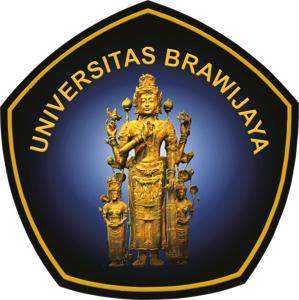

# PENGENALAN ANGKA LISAN BAHASA INDONESIA

## HITUNGIN

**Whisper · Fine-tuning · Evaluasi Numerik**

Notebook eksperimen pembelajaran mesin · LOGICODIX 2026  
Universitas Brawijaya · Malang · 2026

**Penyusun: Tim HITUNGIN**

</div>

---

**Alur CRISP-DM:** Pemahaman Bisnis → Pemahaman Data → Persiapan Data → Pemodelan → Evaluasi → Deployment.

**Cara menjalankan:** pilih runtime GPU T4 di Google Colab, kemudian jalankan sel secara berurutan.
Profil `poc` adalah eksperimen terbatas yang benar-benar melatih dan mengevaluasi model;
ubah `HITUNGIN_PROFILE=full` sebelum sel konfigurasi untuk eksperimen lebih panjang.
Hasil pengenalan selalu dikonfirmasi pengguna sebelum dinilai dengan aturan matematika.
Logo merupakan identitas cover, bukan tanda pengesahan universitas.


## Petunjuk reproduksi

Notebook ini mandiri: mengunduh data publik bila belum tersedia, menetapkan seed,
mencatat versi paket, dan menyimpan artefak di `artifacts/`. Direktori runtime Colab
bersifat sementara. Unduh ZIP artefak di akhir sebelum menutup sesi.
Nilai metrik tidak diisi manual; semuanya dihitung oleh sel evaluasi.


In [1]:
# @title Instalasi dependensi
%pip -q install requests pandas numpy matplotlib scikit-learn soundfile jiwer transformers==4.52.0 accelerate==1.12.0


In [2]:
# @title Konfigurasi eksperimen dan utilitas

import os, sys, json, random, time, copy, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path('/content/hitungin') if Path('/content').exists() else Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
ROOT.mkdir(parents=True, exist_ok=True)
PROFILE = os.environ.get('HITUNGIN_PROFILE', 'poc')
assert PROFILE in {'poc', 'full'}
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
print({'profil': PROFILE, 'perangkat': str(DEVICE), 'python': platform.python_version(),
       'torch': torch.__version__, 'root': str(ROOT)})
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=str) + '\n')

def save_environment(folder):
    import importlib.metadata as metadata
    names = ['torch', 'numpy', 'pandas', 'scikit-learn', 'onnx', 'onnxruntime',
             'transformers', 'accelerate', 'jiwer', 'soundfile']
    versions = {}
    for name in names:
        try: versions[name] = metadata.version(name)
        except metadata.PackageNotFoundError: pass
    save_json(folder / 'environment.json', versions)

def index_artifacts(folder):
    records = []
    for path in sorted(folder.rglob('*')):
        if path.is_file() and path.name != 'manifest.json':
            sha = hashlib.sha256()
            with path.open('rb') as handle:
                for block in iter(lambda: handle.read(1024*1024), b''): sha.update(block)
            records.append({'file': str(path.relative_to(folder)), 'bytes': path.stat().st_size,
                            'sha256': sha.hexdigest()})
    save_json(folder / 'manifest.json', records)
    return pd.DataFrame(records)


{'profil': 'poc', 'perangkat': 'cuda', 'python': '3.13.16', 'torch': '2.14.1+cu130', 'root': '/content/hitungin'}
GPU: Tesla T4


# 1. Pemahaman Bisnis

**Tujuan:** mengenali angka lisan Bahasa Indonesia secara lokal, lalu meminta
konfirmasi pengguna. Notebook memakai checkpoint Whisper Small yang telah
dilatih untuk Bahasa Indonesia, mengevaluasi baseline, kemudian melakukan
fine-tuning terbatas pada connected digits sebagai eksperimen PoC.

**Perbedaan penting:** CDSR berisi urutan digit, misalnya “dua lima” → `25`,
bukan korpus bilangan kardinal “dua puluh lima”. Karena itu metrik training
di sini adalah **digit sequence exact match**, CER numerik, dan WER. Keberhasilan
di CDSR tidak membuktikan keberhasilan bilangan kardinal 0–100 atau suara anak.
Parser bilangan kardinal diuji terpisah dengan fixture teks, bukan diklaim
sebagai hasil evaluasi audio. Fine-tuning digit bisa menurunkan kemampuan umum.

| Tahap | Rancangan |
|---|---|
| Baseline | Bagus/whisper-small-id-cv17, tanpa perubahan bobot |
| Eksperimen | Fine-tuning Whisper dengan learning rate kecil |
| Pemilihan model | Baseline vs fine-tuned berdasarkan validasi speaker terpisah |
| Evaluasi akhir | Hanya model terpilih, sekali pada subset test terpisah |
| Inferensi produk | Lokal di browser; notebook GPU bukan benchmark browser |


In [3]:
# @title Parameter eksperimen dan batas biaya komputasi
import re,zipfile,concurrent.futures,threading
import requests,soundfile as sf
from torch.utils.data import Dataset,DataLoader
from transformers import WhisperProcessor,WhisperForConditionalGeneration,get_linear_schedule_with_warmup
from jiwer import wer
ART=ROOT/'artifacts/suara_indonesia';ART.mkdir(parents=True,exist_ok=True)
DATA=ROOT/'data';DATA.mkdir(exist_ok=True)
CONFIG={'seed':SEED,'model_id':'Bagus/whisper-small-id-cv17','run_finetune':True,
        'train_limit':8440 if PROFILE=='full' else 512,
        'val_limit':512 if PROFILE=='full' else 64,'test_limit':1000 if PROFILE=='full' else 64,
        'max_steps':1000 if PROFILE=='full' else 40,'batch_size':4,'gradient_accumulation':2,
        'lr':1e-5,'max_new_tokens':64,'max_audio_seconds':20}
COMMIT='b2eefc10fc649149cdb634c74e23af26d6a210c8'
SOURCE=DATA/'raw/speech'/f'data_indsp_digit_cdsr-{COMMIT}'
display(pd.Series(CONFIG))
if CONFIG['run_finetune'] and DEVICE.type!='cuda':
    raise RuntimeError('Aktifkan GPU Colab untuk fine-tuning, atau set run_finetune=False untuk baseline CPU.')


,0
seed,42
model_id,Bagus/whisper-small-id-cv17
run_finetune,True
train_limit,512
val_limit,64
test_limit,64
max_steps,40
batch_size,4
gradient_accumulation,2
lr,0.00001


# 2. Pemahaman Data

[INDspeech_DIGIT_CDSR](https://github.com/s-sakti/data_indsp_digit_cdsr)
memiliki 12.444 rekaman publik, mono 16 kHz/16 bit, dari penutur dewasa.
Lisensi CC BY-NC-SA 4.0 dan pembatasan penyalinan publik dari pembuat dataset
disimpan bersama metadata. Notebook tidak mengunggah ulang rekaman.

Audit sebelumnya menemukan empat ID penutur pada train dan test resmi.
Kita membuang semua ID test yang ada di training resmi, kemudian membagi
training menjadi fit/validasi berdasarkan ID penutur. Profil PoC mengambil
beberapa penutur dan rekaman dari setiap partisi untuk menghemat waktu.


In [4]:
# @title Unduh daftar sumber kecil dan bangun indeks rekaman
BASE=f'https://raw.githubusercontent.com/s-sakti/data_indsp_digit_cdsr/{COMMIT}'
def get_source(relative):
    path=SOURCE/relative;path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists():
        response=requests.get(f'{BASE}/{relative}',timeout=60);response.raise_for_status();path.write_bytes(response.content)
    return path

get_source('README.md');get_source('LICENSE_CC-BY-NC-SA-4.0.txt')
rows=[]
for split in ['train','test1','test2','test3','test4']:
    stems=get_source(f'lst/{split}_fname.lst').read_text().split()
    for stem in stems:
        rows.append({'split':split,'stem':stem,'speaker':stem.split('_')[0]})
index=pd.DataFrame(rows)
display(index.groupby('split').agg(rekaman=('stem','size'),penutur=('speaker','nunique')))
display(index.head())


,rekaman,penutur
split,,
test1,1001,104
test2,1001,104
test3,1001,104
test4,1001,104
train,8440,110


,split,stem,speaker
0,train,FAC_00483A,FAC
1,train,FAC_01004A,FAC
2,train,FAC_0228505A,FAC
3,train,FAC_05214A,FAC
4,train,FAC_075A,FAC


# 3. Persiapan Data

Audio dipertahankan pada 16 kHz. Feature extractor Whisper membuat log-Mel
spectrogram; tokenizer Bahasa Indonesia menghasilkan token referensi.
Token awal decoder dilepas pada batch label karena model menambahkannya sendiri.
Padding label diganti `-100` agar tidak dihitung dalam loss.

Data kalibrasi tidak dipakai untuk update gradien. Seleksi baseline vs model
fine-tuned mengikuti exact-match numerik validasi, dengan WER sebagai tie-break.
Batas rekaman dan jumlah langkah dicatat; profil PoC bukan training konvergen.


In [5]:
# @title Split berdasarkan penutur dan ambil subset PoC yang tetap
rng=np.random.default_rng(SEED)
official_train=set(index.loc[index.split=='train','speaker'])
official_test=set(index.loc[index.split!='train','speaker'])
overlap=sorted(official_train & official_test)
speakers=sorted(official_train);rng.shuffle(speakers)
n_val=max(1,round(len(speakers)*0.2))
val_speakers=set(speakers[:n_val]);fit_speakers=set(speakers[n_val:])
test_speakers=official_test-official_train
def balanced_speakers(candidates,limit):
    """Seimbangkan prefix F/M sesuai metadata penutur pada dataset sumber."""
    chosen=[];local_rng=np.random.default_rng(SEED)
    for prefix in ['F','M']:
        group=sorted(s for s in candidates if s.startswith(prefix))
        local_rng.shuffle(group);chosen.extend(group[:limit//2])
    return set(chosen)

if PROFILE=='poc':
    fit_speakers=balanced_speakers(fit_speakers,16)
    val_speakers=balanced_speakers(val_speakers,8)
    test_speakers=balanced_speakers(test_speakers,8)
assert not (fit_speakers&val_speakers or fit_speakers&test_speakers or val_speakers&test_speakers)

def select_rows(mask,limit):
    frame=index.loc[mask].sample(frac=1,random_state=SEED).head(limit).copy()
    return frame.reset_index(drop=True)

fit=select_rows((index.split=='train')&index.speaker.isin(fit_speakers),CONFIG['train_limit'])
val=select_rows((index.split=='train')&index.speaker.isin(val_speakers),CONFIG['val_limit'])
test=select_rows((index.split!='train')&index.speaker.isin(test_speakers),CONFIG['test_limit'])
split_report={'excluded_overlapping_speaker_ids':overlap,'fit_speakers':sorted(fit_speakers),
              'val_speakers':sorted(val_speakers),'test_speakers':sorted(test_speakers),
              'fit_recordings':len(fit),'val_recordings':len(val),'test_recordings':len(test)}
display(pd.Series(split_report));save_json(ART/'split.json',split_report)
display(pd.DataFrame({'partisi':['fit','validasi','test'],
                      'prefix_F':[sum(s.startswith('F') for s in group) for group in [fit_speakers,val_speakers,test_speakers]],
                      'prefix_M':[sum(s.startswith('M') for s in group) for group in [fit_speakers,val_speakers,test_speakers]]}))


,0
excluded_overlapping_speaker_ids,"[FAM, MAF, MDM, MJL]"
fit_speakers,"[FNT, FOC, FPT, FRA, FRT, FRY, FZD, FZF, MAF, ..."
val_speakers,"[FAC, FOB, FRI, FRP, MDM, MDS, MMI, MYI]"
test_speakers,"[FEY, FPR, FTT, FYB, MAO, MJK, MMY, MSA]"
fit_recordings,512
val_recordings,64
test_recordings,64


,partisi,prefix_F,prefix_M
0,fit,8,8
1,validasi,4,4
2,test,4,4


Arsip penutur selesai: 10 / 52
Arsip penutur selesai: 20 / 52
Arsip penutur selesai: 30 / 52
Arsip penutur selesai: 40 / 52
Arsip penutur selesai: 50 / 52


,count,mean,std,min,25%,50%,75%,max
partisi,,,,,,,,
test,64.0,3.673310,1.325393,2.152438,2.587219,3.314031,4.408516,8.800000
train,512.0,3.580924,1.061611,2.008375,2.712203,3.360812,4.193531,7.235688
val,64.0,3.493079,0.979336,2.155438,2.780813,3.229469,3.933734,6.973312


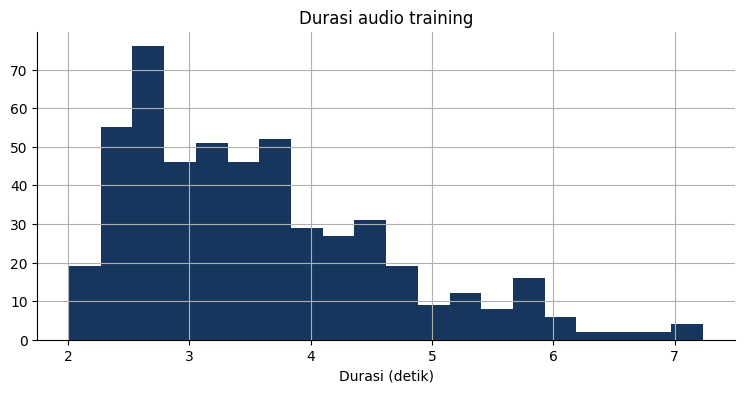

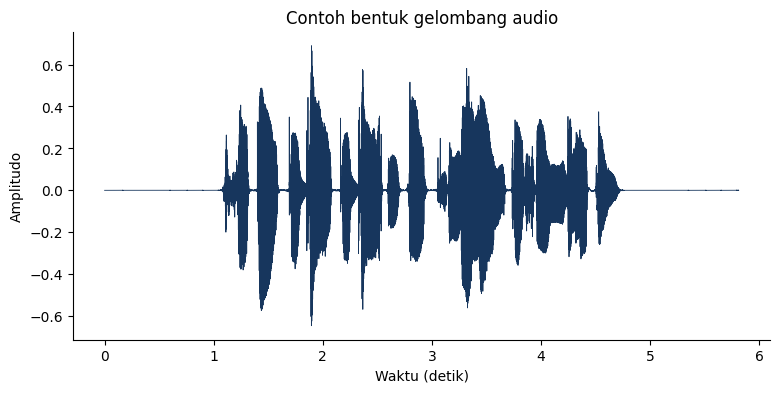

Referensi: satu tiga tiga empat sembilan kosong delapan


In [6]:
# @title Unduh hanya arsip penutur yang dipakai dan ekstrak dengan aman
selected=pd.concat([fit,val,test],ignore_index=True)
def prepare_speaker(pair):
    split,speaker=pair
    for group in ['speech','text']:
        path=SOURCE/group/split/f'{speaker}.zip'
        target=path.parent/speaker
        suffix='.wav' if group=='speech' else '.txt'
        needed=selected.loc[(selected.split==split)&(selected.speaker==speaker),'stem']
        if any(not list(target.rglob(stem+suffix)) for stem in needed):
            path=get_source(f'{group}/{split}/{speaker}.zip')
            target.mkdir(parents=True,exist_ok=True)
            with zipfile.ZipFile(path) as archive:
                for member in archive.infolist():
                    assert (target/member.filename).resolve().is_relative_to(target.resolve())
                    archive.extract(member,target)
    return pair

pairs=list(selected[['split','speaker']].drop_duplicates().itertuples(index=False,name=None))
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as pool:
    for count,_ in enumerate(pool.map(prepare_speaker,pairs),1):
        if count%10==0:print('Arsip penutur selesai:',count,'/',len(pairs))

def attach_paths(frame):
    result=frame.copy();wavs=[];texts=[];durations=[]
    for row in result.itertuples():
        audio=list((SOURCE/'speech'/row.split/row.speaker).rglob(row.stem+'.wav'))
        transcript=list((SOURCE/'text'/row.split/row.speaker).rglob(row.stem+'.txt'))
        assert len(audio)==len(transcript)==1,(row.stem,audio,transcript)
        words=[line.strip().lower() for line in transcript[0].read_text().splitlines() if line.strip() and not line.startswith('|')]
        info=sf.info(audio[0]);assert info.samplerate==16000 and info.channels==1
        wavs.append(str(audio[0]));texts.append(' '.join(words));durations.append(info.duration)
    result['audio']=wavs;result['reference']=texts;result['seconds']=durations
    return result[result.seconds<=CONFIG['max_audio_seconds']].reset_index(drop=True)

fit,val,test=map(attach_paths,[fit,val,test])
for name,frame in [('train',fit),('val',val),('test',test)]:
    assert len(frame)>0
    frame.drop(columns='audio').to_csv(ART/f'{name}_index.csv',index=False)
display(pd.concat([f.assign(partisi=n) for n,f in [('train',fit),('val',val),('test',test)]]).groupby('partisi').seconds.describe())
fit.seconds.hist(bins=20,color='#17365d');plt.xlabel('Durasi (detik)');plt.title('Durasi audio training');plt.show()
preview,sr=sf.read(fit.iloc[0].audio,dtype='float32')
plt.plot(np.arange(len(preview))/sr,preview,color='#17365d',linewidth=0.6)
plt.xlabel('Waktu (detik)');plt.ylabel('Amplitudo');plt.title('Contoh bentuk gelombang audio');plt.show()
print('Referensi:',fit.iloc[0].reference)
# Dengarkan lewat panel Files Colab. Audio tidak disematkan dalam notebook hasil.


In [7]:
# @title Normalisasi digit dan parser bilangan kardinal yang terpisah
DIGIT_WORDS={'nol':'0','kosong':'0','satu':'1','dua':'2','tiga':'3','empat':'4','lima':'5',
             'enam':'6','tujuh':'7','delapan':'8','sembilan':'9'}

def numeric_sequence(text):
    tokens=re.findall(r'\d+|[a-z]+',text.lower())
    if not tokens:return None
    result=[]
    for token in tokens:
        if token.isdigit():result.append(token)
        elif token in DIGIT_WORDS:result.append(DIGIT_WORDS[token])
        else:return None
    return ''.join(result)

def parse_cardinal(text):
    tokens=re.findall(r'\d+|[a-z]+',text.lower())
    if len(tokens)==1 and tokens[0].isdigit():
        value=int(tokens[0]);return value if 0<=value<=100 else None
    small={k:int(v) for k,v in DIGIT_WORDS.items()}
    if len(tokens)==1:
        return {'sepuluh':10,'sebelas':11,'seratus':100}.get(tokens[0],small.get(tokens[0]))
    if len(tokens)==2 and tokens[0] in small and 2<=small[tokens[0]]<=9 and tokens[1]=='belas':
        return small[tokens[0]]+10
    if len(tokens) in [2,3] and tokens[0] in small and 2<=small[tokens[0]]<=9 and tokens[1]=='puluh':
        if len(tokens)==2:return small[tokens[0]]*10
        if tokens[2] in small and 1<=small[tokens[2]]<=9:return small[tokens[0]]*10+small[tokens[2]]
    return None

def spell_cardinal(value):
    words=['nol','satu','dua','tiga','empat','lima','enam','tujuh','delapan','sembilan']
    if value<10:return words[value]
    if value==10:return 'sepuluh'
    if value==11:return 'sebelas'
    if value<20:return words[value-10]+' belas'
    if value==100:return 'seratus'
    return words[value//10]+' puluh'+(' '+words[value%10] if value%10 else '')

assert all(parse_cardinal(spell_cardinal(i))==i for i in range(101))
assert all(parse_cardinal(s) is None for s in ['dua atau tiga','101','satu dua','dua puluh nol'])
assert parse_cardinal('dua puluh')==20
print('Fixture parser 0–100 lulus. Parser tidak menerima kunci jawaban soal.')


Fixture parser 0–100 lulus. Parser tidak menerima kunci jawaban soal.


# 4. Pemodelan

Gunakan checkpoint pretrained Bahasa Indonesia sebagai baseline; tidak melatih
ASR dari nol. Fine-tuning memakai optimizer AdamW, gradient accumulation,
mixed precision di GPU, gradient clipping, dan warmup. Hanya data fit yang
memperbarui bobot. Decoder menggunakan bahasa Indonesia dan tugas transkripsi.

Profil PoC membatasi 40 optimizer steps. Untuk penelitian lebih lanjut, tambah
langkah dan lakukan evaluasi konvergensi. Model terpilih boleh tetap baseline
jika fine-tuning tidak memperbaiki validasi.
Versi Transformers dipatok untuk menghindari regresi backward Whisper yang
ditemukan saat pengujian. Notebook diuji ulang dengan 4.52.0 dan checkpointing
non-reentrant.


In [8]:
# @title Muat processor, model pretrained, dan identitas revisinya
processor=WhisperProcessor.from_pretrained(CONFIG['model_id'],language='Indonesian',task='transcribe',token=False)
model=WhisperForConditionalGeneration.from_pretrained(CONFIG['model_id'],token=False).to(DEVICE)
model.generation_config.language='indonesian';model.generation_config.task='transcribe'
model.generation_config.forced_decoder_ids=None
model.config.forced_decoder_ids=None
save_json(ART/'source_model.json',{'id':CONFIG['model_id'],'revision':getattr(model.config,'_commit_hash',None),
          'dataset_commit':COMMIT})

class SpeechDataset(Dataset):
    def __init__(self,frame):self.frame=frame.reset_index(drop=True)
    def __len__(self):return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i];audio,sr=sf.read(row.audio,dtype='float32')
        features=processor.feature_extractor(audio,sampling_rate=sr).input_features[0]
        labels=processor.tokenizer(row.reference).input_ids
        return {'input_features':features,'labels':labels}

def collate_speech(batch):
    features=processor.feature_extractor.pad([{'input_features':b['input_features']} for b in batch],return_tensors='pt')
    labels=processor.tokenizer.pad([{'input_ids':b['labels']} for b in batch],return_tensors='pt')
    ids=labels.input_ids.masked_fill(labels.attention_mask.ne(1),-100)
    if (ids[:,0]==model.config.decoder_start_token_id).all():ids=ids[:,1:]
    return {'input_features':features.input_features,'labels':ids}

def evaluate_speech(network,frame):
    network.eval();records=[]
    with torch.no_grad():
        for start in range(0,len(frame),4):
            chunk=frame.iloc[start:start+4];audios=[sf.read(p,dtype='float32')[0] for p in chunk.audio]
            inputs=processor(audios,sampling_rate=16000,return_tensors='pt',return_attention_mask=True)
            tick=time.perf_counter()
            generated=network.generate(inputs.input_features.to(DEVICE),attention_mask=inputs.attention_mask.to(DEVICE),
                                       max_new_tokens=CONFIG['max_new_tokens'],do_sample=False)
            if DEVICE.type=='cuda':torch.cuda.synchronize()
            seconds=time.perf_counter()-tick
            predictions=processor.batch_decode(generated,skip_special_tokens=True)
            for row,prediction in zip(chunk.itertuples(),predictions):
                reference=numeric_sequence(row.reference);predicted=numeric_sequence(prediction)
                records.append({'stem':row.stem,'reference':row.reference,'prediction':prediction,
                    'reference_digits':reference,'predicted_digits':predicted,'correct':reference==predicted,
                    'rejected':predicted is None,'seconds_per_item_batch':seconds/len(chunk)})
    results=pd.DataFrame(records)
    edits=sum(digit_edit_distance(r.reference_digits,r.predicted_digits or '') for r in results.itertuples())
    total=sum(len(s) for s in results.reference_digits)
    metrics={'digit_sequence_exact_match':float(results.correct.mean()),'numeric_cer':edits/total,
             'wer':wer(results.reference.tolist(),results.prediction.str.lower().tolist()),
             'rejection_rate':float(results.rejected.mean()),'samples':len(results)}
    return metrics,results

def digit_edit_distance(a,b):
    row=list(range(len(b)+1))
    for i,ca in enumerate(a,1):
        nxt=[i]
        for j,cb in enumerate(b,1):nxt.append(min(nxt[-1]+1,row[j]+1,row[j-1]+(ca!=cb)))
        row=nxt
    return row[-1]


preprocessor_config.json:   0%|          | 0.00/339 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


vocab.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (2 outputs left out)

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/967M [00:00<?, ?B/s]

generation_config.json: 0.00B [00:00, ?B/s]

In [9]:
# @title Ukur baseline pada validasi, bukan test
baseline_metrics,baseline_predictions=evaluate_speech(model,val)
display(pd.Series(baseline_metrics,name='baseline_validasi'))
baseline_predictions.to_csv(ART/'baseline_val_predictions.csv',index=False)
save_json(ART/'baseline_val_metrics.json',baseline_metrics)


,baseline_validasi
digit_sequence_exact_match,0.875000
numeric_cer,0.097561
wer,0.400000
rejection_rate,0.109375
samples,64.000000


/tmp/ipykernel_1666/1556522752.py:19: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer);scaler.update();scheduler.step();optimizer.zero_grad();step+=1


{'step': 5, 'loss': 0.23582258448004723, 'lr': 9.722222222222223e-06}


{'step': 10, 'loss': 0.0053668898763135076, 'lr': 8.333333333333334e-06}


{'step': 15, 'loss': 0.09536824396491284, 'lr': 6.944444444444445e-06}


{'step': 20, 'loss': 0.005903618526645005, 'lr': 5.555555555555557e-06}


{'step': 25, 'loss': 0.00037663148395949975, 'lr': 4.166666666666667e-06}


{'step': 30, 'loss': 0.00031008567566459533, 'lr': 2.7777777777777783e-06}


{'step': 35, 'loss': 0.0013046679687249707, 'lr': 1.3888888888888892e-06}


{'step': 40, 'loss': 0.0011502536399348173, 'lr': 0.0}
Durasi fine-tuning (detik): 48.031439834000025


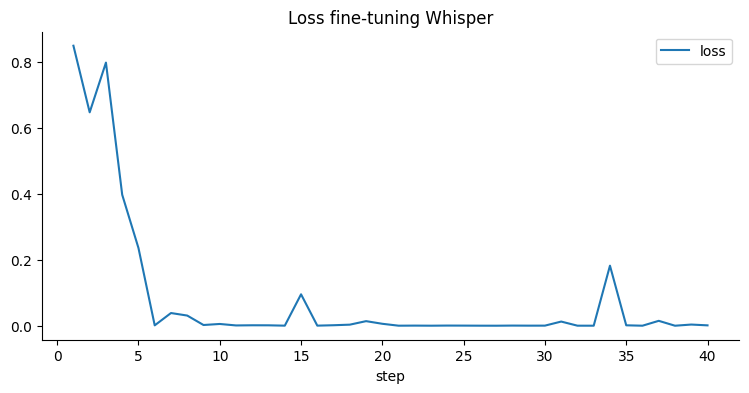

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3464: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 448, 'suppress_tokens': [1, 2, 7, 8, 9, 10, 14, 25, 26, 27, 28, 29, 31, 58, 59, 60, 61, 62, 63, 90, 91, 92, 93, 359, 503, 522, 542, 873, 893, 902, 918, 922, 931, 1350, 1853, 1982, 2460, 2627, 3246, 3253, 3268, 3536, 3846, 3961, 4183, 4667, 6585, 6647, 7273, 9061, 9383, 10428, 10929, 11938, 12033, 12331, 12562, 13793, 14157, 14635, 15265, 15618, 16553, 16604, 18362, 18956, 20075, 21675, 22520, 26130, 26161, 26435, 28279, 29464, 31650, 32302, 32470, 36865, 42863, 47425, 49870, 50254, 50258, 50360, 50361, 50362], 'begin_suppress_tokens': [220, 50257]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


,digit_sequence_exact_match,numeric_cer,wer,rejection_rate,samples
baseline,0.875000,0.097561,0.400000,0.109375,64
fine_tuned,0.984375,0.004878,0.004878,0.000000,64


In [10]:
# @title Fine-tuning terbatas pada GPU
history=[];finetuned_metrics=None
if CONFIG['run_finetune']:
    model.train();model.config.use_cache=False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
    loader=DataLoader(SpeechDataset(fit),batch_size=CONFIG['batch_size'],shuffle=True,collate_fn=collate_speech,num_workers=0)
    optimizer=torch.optim.AdamW(model.parameters(),lr=CONFIG['lr'],weight_decay=0.01)
    scheduler=get_linear_schedule_with_warmup(optimizer,num_warmup_steps=max(1,CONFIG['max_steps']//10),num_training_steps=CONFIG['max_steps'])
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE.type=='cuda')
    optimizer.zero_grad();step=0;micro=0;loss_sum=0;started=time.perf_counter()
    while step<CONFIG['max_steps']:
        for batch in loader:
            batch={k:v.to(DEVICE) for k,v in batch.items()}
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=DEVICE.type=='cuda',cache_enabled=False):
                loss=model(**batch).loss/CONFIG['gradient_accumulation']
            scaler.scale(loss).backward();micro+=1;loss_sum+=loss.item()*CONFIG['gradient_accumulation']
            if micro%CONFIG['gradient_accumulation']==0:
                scaler.unscale_(optimizer);torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
                scaler.step(optimizer);scaler.update();scheduler.step();optimizer.zero_grad();step+=1
                history.append({'step':step,'loss':loss_sum/CONFIG['gradient_accumulation'],'lr':scheduler.get_last_lr()[0]});loss_sum=0
                if step%5==0:print(history[-1])
                if step>=CONFIG['max_steps']:break
    print('Durasi fine-tuning (detik):',time.perf_counter()-started)
    model.gradient_checkpointing_disable();model.config.use_cache=True
    pd.DataFrame(history).to_csv(ART/'history.csv',index=False)
    pd.DataFrame(history).plot(x='step',y='loss',title='Loss fine-tuning Whisper');plt.show()
    model.save_pretrained(ART/'candidate_finetuned');processor.save_pretrained(ART/'candidate_finetuned')
    finetuned_metrics,finetuned_predictions=evaluate_speech(model,val)
    finetuned_predictions.to_csv(ART/'finetuned_val_predictions.csv',index=False)
    save_json(ART/'finetuned_val_metrics.json',finetuned_metrics)
    display(pd.DataFrame([baseline_metrics,finetuned_metrics],index=['baseline','fine_tuned']))


# 5. Evaluasi

Pilihan model ditetapkan dari validasi saja. Test digunakan setelah keputusan
itu terkunci. Selain exact-match, laporkan penolakan dan kesalahan urutan digit;
leading zeros penting dalam CDSR dan tidak boleh dibuang sebelum evaluasi.
WER mengukur transkrip, bukan langsung ketepatan bilangan kardinal.


In [11]:
# @title Pilih model dari validasi dan jalankan evaluasi akhir
def score(metrics):return (metrics['digit_sequence_exact_match'],-metrics['wer'])
choose_finetuned=finetuned_metrics is not None and score(finetuned_metrics)>score(baseline_metrics)
chosen='fine_tuned' if choose_finetuned else 'baseline'
if not choose_finetuned and CONFIG['run_finetune']:
    del optimizer,scaler,scheduler,model
    if torch.cuda.is_available():torch.cuda.empty_cache()
    model=WhisperForConditionalGeneration.from_pretrained(CONFIG['model_id'],token=False).to(DEVICE)
    model.generation_config.language='indonesian';model.generation_config.task='transcribe'
    model.generation_config.forced_decoder_ids=None
test_metrics,test_predictions=evaluate_speech(model,test)
test_metrics.update(chosen_model=chosen,cardinal_audio_evaluated=False,child_speech_evaluated=False,browser_benchmarked=False)
display(pd.Series(test_metrics));display(test_predictions[~test_predictions.correct].head(20))
save_json(ART/'metrics.json',test_metrics);test_predictions.to_csv(ART/'test_predictions.csv',index=False)
save_json(ART/'selection.json',{'chosen':chosen,'criterion':'validation digit exact-match, then lower WER',
          'baseline_val':baseline_metrics,'finetuned_val':finetuned_metrics})


,0
digit_sequence_exact_match,1.0
numeric_cer,0.0
wer,0.0
rejection_rate,0.0
samples,64
chosen_model,fine_tuned
cardinal_audio_evaluated,False
child_speech_evaluated,False
browser_benchmarked,False


,stem,reference,prediction,reference_digits,predicted_digits,correct,rejected,seconds_per_item_batch


# 6. Deployment dan Penyimpanan Model

Simpan model terpilih beserta processor/tokenizer dengan `save_pretrained`.
Direktori ini dapat dimuat ulang tanpa menghubungi model hub. Fine-tuned
candidate disimpan terpisah agar keputusan memilih baseline tetap dapat diaudit.

**Batas deployment:** checkpoint PyTorch bukan model browser. Konversi Whisper
ke ONNX, kuantisasi, dan uji Transformers.js merupakan gerbang terpisah.
Notebook sengaja tidak mengklaim model fine-tuned sudah kompatibel WebGPU.
Baseline ONNX publik dapat diuji terpisah melalui repository `cmaree`.
Token probability Whisper bukan confidence numerik terkalibrasi.


In [12]:
# @title Simpan model final, processor, parser, dan model card
import inspect
FINAL=ART/'model_final'
model.save_pretrained(FINAL,safe_serialization=True);processor.save_pretrained(FINAL)
save_json(ART/'config.json',CONFIG)
parser_source='import re\nDIGIT_WORDS='+repr(DIGIT_WORDS)+'\n\n'+inspect.getsource(numeric_sequence)+'\n\n'+inspect.getsource(parse_cardinal)
(ART/'number_parser.py').write_text(parser_source)
card=f'''# HITUNGIN: pengenalan angka lisan Bahasa Indonesia

Model terpilih: {chosen}
Checkpoint awal: {CONFIG['model_id']}
Dataset: INDspeech_DIGIT_CDSR, commit {COMMIT}
Lisensi dataset: CC BY-NC-SA 4.0; jangan mendistribusikan ulang corpus tanpa izin pembuat.
Metrik: lihat metrics.json; model dipilih memakai validasi, bukan test.
Domain evaluasi: connected digits penutur dewasa. Audio bilangan kardinal dan anak belum diuji.
Status browser: belum dikonversi/dikuantisasi dan belum dibenchmark.
Model ini menghasilkan kandidat transkripsi; konfirmasi pengguna wajib sebelum penilaian matematika.
'''
(ART/'MODEL_CARD.md').write_text(card)


633

In [13]:
# @title Uji muat ulang model final tanpa akses model hub
probe_audio,_=sf.read(test.iloc[0].audio,dtype='float32')
inputs=processor(probe_audio,sampling_rate=16000,return_tensors='pt',return_attention_mask=True)
model.eval()
with torch.no_grad():
    expected=model.generate(inputs.input_features.to(DEVICE),attention_mask=inputs.attention_mask.to(DEVICE),max_new_tokens=64,do_sample=False).cpu()
del model
if torch.cuda.is_available():torch.cuda.empty_cache()
reloaded=WhisperForConditionalGeneration.from_pretrained(FINAL,local_files_only=True).to(DEVICE).eval()
reloaded_processor=WhisperProcessor.from_pretrained(FINAL,local_files_only=True)
with torch.no_grad():
    actual=reloaded.generate(inputs.input_features.to(DEVICE),attention_mask=inputs.attention_mask.to(DEVICE),max_new_tokens=64,do_sample=False).cpu()
assert torch.equal(actual,expected),'Token berubah setelah model dimuat ulang'
print('Muat ulang lulus:',reloaded_processor.batch_decode(actual,skip_special_tokens=True))
save_json(ART/'reload_check.json',{'identical_token_ids':True,'local_files_only':True})
del reloaded
if torch.cuda.is_available():torch.cuda.empty_cache()


`generation_config` default values have been modified to match model-specific defaults: {'suppress_tokens': [1, 2, 7, 8, 9, 10, 14, 25, 26, 27, 28, 29, 31, 58, 59, 60, 61, 62, 63, 90, 91, 92, 93, 359, 503, 522, 542, 873, 893, 902, 918, 922, 931, 1350, 1853, 1982, 2460, 2627, 3246, 3253, 3268, 3536, 3846, 3961, 4183, 4667, 6585, 6647, 7273, 9061, 9383, 10428, 10929, 11938, 12033, 12331, 12562, 13793, 14157, 14635, 15265, 15618, 16553, 16604, 18362, 18956, 20075, 21675, 22520, 26130, 26161, 26435, 28279, 29464, 31650, 32302, 32470, 36865, 42863, 47425, 49870, 50254, 50258, 50360, 50361, 50362], 'begin_suppress_tokens': [220, 50257]}. If this is not desired, please set these values explicitly.


A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.


A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> to see related `.generate()` flags.


Muat ulang lulus: ['enam satu']


## Kesimpulan dan tindak lanjut

Bandingkan baseline dan fine-tuning berdasarkan hasil aktual, bukan asumsi bahwa
fine-tuning selalu lebih baik. Sebelum penggunaan produk, uji audio kardinal
0–100, suara anak, noise kelas, dan runtime browser. ASR tidak boleh memakai
kunci jawaban matematika untuk menebak transkrip yang diinginkan.

**Referensi:** [CDSR dan lisensi](https://github.com/s-sakti/data_indsp_digit_cdsr),
[checkpoint Bahasa Indonesia](https://huggingface.co/Bagus/whisper-small-id-cv17),
[Whisper Transformers](https://huggingface.co/docs/transformers/model_doc/whisper),
[kandidat browser ONNX](https://huggingface.co/cmaree/Bagus-whisper-small-id-onnx).


In [14]:
# @title Buat paket akhir, tanpa menyertakan rekaman dataset
import shutil
save_environment(ART);display(index_artifacts(ART))
# Candidate adalah checkpoint audit; ZIP final hanya memuat model terpilih dan laporan.
package=ART.parent/'suara_package'
if package.exists():shutil.rmtree(package)
shutil.copytree(ART,package,ignore=shutil.ignore_patterns('candidate_finetuned'))
_ = index_artifacts(package)
archive=shutil.make_archive(str(ART.parent/'suara_indonesia'),'zip',package)
from IPython.display import FileLink
display(FileLink(archive));print('Artefak:',archive)


,file,bytes,sha256
0,MODEL_CARD.md,633,a2b5c51e7aa39dd2a19b315a61fc12944a8433be928b43...
1,baseline_val_metrics.json,140,173830b41fd93dfd284caef4d2a3617ddce5b454412b22...
2,baseline_val_predictions.csv,5688,aff7a32f0e5e3933dd140c7884a9b9f45a32f357176518...
3,candidate_finetuned/added_tokens.json,34604,9715fd2243b6f06a5858b5e32950d2853f73dd5bc201aa...
4,candidate_finetuned/config.json,1230,1ed9f9389dab5420dda0980e68dcf77d526e2c0cd24cbd...
5,candidate_finetuned/generation_config.json,3796,af989c4bdf6139209e72f0c506bc9a9622e2f0aecd47c0...
6,candidate_finetuned/merges.txt,493869,2df2990a395e35e8dfbc7511e08c12d56018d8d04691e0...
7,candidate_finetuned/model.safetensors,966995080,296f2c6fba8785cb05dca0ed06b09f512d0d59eaaaef3a...
8,candidate_finetuned/normalizer.json,52666,bf1c507dc8724ca9cf9903640dacfb69dae2f00edee4f2...
9,candidate_finetuned/preprocessor_config.json,356,994838f1fa6462c8b9b3c90edada831f11f3dd8b466463...


/content/hitungin/artifacts/suara_indonesia.zip

Artefak: /content/hitungin/artifacts/suara_indonesia.zip
